# Inference with the Neural Race Model

This tutorial shows how to run the **released NRM checkpoints** on stimulus
embeddings, for the three benchmarks of the paper:

| task | choices | input embedding (`covariates`) | checkpoint |
|---|---|---|---|
| Random-dot motion (RDM) | left / right | motion energy, **150 frames × 24** (8 directions × 3 speeds, 75 Hz) | `nrm/weights/NRM_rdm.pth` |
| Scene categorisation (SC) | natural / man-made | DINOv2-S/14 patch-mean, **18-d** | `nrm/weights/NRM_sc.pt` |
| Speed–accuracy trade-off (SAT) | 16 ImageNet categories | DINOv2-S/14 patch-mean, **384-d**, plus the **deadline** (s) | `nrm/weights/NRM_sat_{blur,color,noise}.pth` |

For one stimulus the model is a race between one accumulator per alternative:

$$dX_i = f_\theta(X_i, c)\,dt + g_\phi(X_i, c)\,dW_i,\qquad
\text{choice} = \arg\min_i \inf\{t : X_i(t) \ge \Theta(c)\},$$

where $c$ is the embedding encoded by the conditioning network. Two calls do
all the work:

* **`model.simulate_nDDM(batch_size, covariates, soft=True, n_reps, t=0.993)`**
  integrates the SDE and returns the paths `xs`, the time grid `ts`, and for
  each stimulus the modal choice and median RT over its `n_reps` races. 
* **`model.forward_pass(covariates, batch_size, n_reps)`** returns the differentiable quantities used to compute the training loss: the choice probabilities, obtained via a softmax over accumulated evidence, and the first-passage-time density.

The race is stochastic, so a prediction is a *distribution* of choices and RTs.
To get every sample rather than the mode/median, repeat each stimulus along
the batch and use `n_reps=1`, exactly as the evaluators do.

**Before running:** `python fetch_assets.py` (data and embeddings).
The last cell of each section renders the race as a GIF (`assets/nrm_*.gif`);
the RDM video needs `opencv-python`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'tutorial' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from nrm.config import build_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42


def seed_all(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)


def load_nrm(benchmark, weight):
    """Build the architecture of `benchmark` (nrm/config.py) and load its weights."""
    model = build_model(benchmark, device=device)
    ckpt = torch.load(ROOT / 'nrm' / 'weights' / weight, map_location=device)
    model.load_state_dict(ckpt.get('model_state_dict', ckpt))
    return model.eval()


@torch.no_grad()
def sample_races(model, covariates, n_samples=500):
    """Choice and RT of `n_samples` independent races for each stimulus.

    covariates: dict of tensors whose first dimension indexes stimuli (B).
    Returns choices and rts of shape (B, n_samples); a race that never reaches
    the bound has choice -1 and rt = model.t_max.
    """
    B = next(iter(covariates.values())).shape[0]
    rep = {k: v.repeat_interleave(n_samples, dim=0) for k, v in covariates.items()}
    _, _, choices, rts = model.simulate_nDDM(batch_size=B * n_samples, covariates=rep,
                                             soft=True, n_reps=1, t=0.993)
    return choices.view(B, n_samples).cpu().numpy(), rts.view(B, n_samples).cpu().numpy()


def summarise(choices, rts, labels, target, human_rt=None):
    """Print the predicted choice distribution and RT for one stimulus."""
    p = [(choices == k).mean() for k in range(len(labels))]
    top = np.argsort(p)[::-1][:3]
    print('  P(choice):', ', '.join(f'{labels[k]} {p[k]:.2f}' for k in top if p[k] > 0))
    print(f'  P(correct = {labels[target]}): {p[target]:.2f}')
    print(f'  model RT: median {np.median(rts)*1000:.0f} ms '
          f'(IQR {np.percentile(rts, 25)*1000:.0f}–{np.percentile(rts, 75)*1000:.0f} ms)'
          + (f'   ·   human RT {human_rt*1000:.0f} ms' if human_rt is not None else ''))


def plot_rt(ax, rts, choices, target, density, ts, human_rt, title, t_max):
    """Sampled RT histogram (correct / error), forward_pass density, human RT."""
    bins = np.linspace(0, t_max, 61)
    w = 1.0 / (len(rts) * (bins[1] - bins[0]))      # correct + error integrate to 1
    ax.hist([rts[choices == target], rts[choices != target]], bins=bins, stacked=True,
            weights=[np.full((choices == target).sum(), w), np.full((choices != target).sum(), w)],
            color=['#2B59C3', '#D64545'], alpha=.7, label=['samples: correct', 'samples: error'])
    ax.plot(ts, density / (ts[1] - ts[0]), color='#1B2433', lw=1.5,
            label='forward_pass density')
    if human_rt is not None:
        ax.axvline(human_rt, color='#C98A00', ls='--', lw=1.5, label='human RT')
    ax.set(title=title, xlabel='time (s)', xlim=(0, t_max))
    ax.legend(fontsize=8)

## 1. Random-dot motion

### Model
`build_model('rdm')` is a `TimeEmbeddedNRM`: the conditioning is a *sequence*,
one vector per video frame, so drift, diffusion and bound can change during
the trial.

In [2]:
rdm = load_nrm('rdm', 'NRM_rdm.pth')
print(type(rdm).__name__, '| choices:', rdm.n_choices, '| t_max:', rdm.t_max, 's | dt:', rdm.dt,
      's | frame rate:', rdm.fs, 'Hz')
RDM_LABELS = ['right', 'left']      # direction 0° / 180° (direction_label 0 / 1)

TimeEmbeddedNRM | choices: 2 | t_max: 3.0 s | dt: 0.01 s | frame rate: 75 Hz


### Stimulus embeddings
`embeddings/rdm/rdm_embeddings.pt` holds the motion-energy embedding of every
video, `[150 frames, 24 channels]`. We load the held-out test split the paper
evaluates on and pick one typical trial at the strongest and one at a weak
coherence.

In [3]:
from datasets.rdm.loader import load_rdm_nrm_dataset
from tutorial.make_gifs import typical_trial

ds = load_rdm_nrm_dataset(pkl_out=ROOT / 'datasets/rdm/rdm_nrm_dataset.pkl',
                          embeddings_path=ROOT / 'embeddings/rdm/rdm_embeddings.pt')
ds.remove_rt_outliers_mad(mad_thresh=3.0, min_rt=0.05, max_rt=3.0)
_, _, rdm_test = ds.train_val_test_split(val_size=0.10, test_size=0.10, seed=42)
rdm_df = rdm_test.df.reset_index(drop=True)
rdm_df['_correct'], rdm_df['_rt'] = rdm_df['correct'], rdm_df['rt']

rng = np.random.default_rng(SEED)
rdm_trials = {name: typical_trial(rdm_df, np.isclose(rdm_df['coherence'], coh), rng)
              for name, coh in (('easy', 51.2), ('hard', 3.2))}
print('embeddings:', tuple(rdm_test.embeddings.shape), '(trials, frames, channels)')
rdm_df.loc[list(rdm_trials.values()), ['coherence', 'direction', 'rt', 'human_choice']]

Loading RDM metadata from datasets/rdm/rdm_nrm_dataset.pkl ...
Loading embeddings from embeddings/rdm/rdm_embeddings.pt ...
RT outlier removal (MAD per coherence, thresh=3.0, min_rt=0.05s, max_rt=3.0s): 3386 removed, 55052 remaining.
  train:  44161 trials
  val  :   5453 trials
  test :   5438 trials
embeddings: (5438, 150, 24) (trials, frames, channels)


,coherence,direction,rt,human_choice
446,51.2,180,0.485865,1
4163,3.2,180,0.679398,1


### Inference on one stimulus
The covariates are a dict; the embedding goes under `'img_embedding'` with a
batch dimension: `[1, 150, 24]`.

easy: 51.2% coherence, dots move left
  P(choice): left 0.96, right 0.04
  P(correct = left): 0.96
  model RT: median 542 ms (IQR 441–652 ms)   ·   human RT 486 ms
  forward_pass choice probabilities: [0.01 0.99]
hard: 3.2% coherence, dots move left
  P(choice): left 0.83, right 0.17
  P(correct = left): 0.83
  model RT: median 627 ms (IQR 502–803 ms)   ·   human RT 679 ms
  forward_pass choice probabilities: [0.04 0.96]


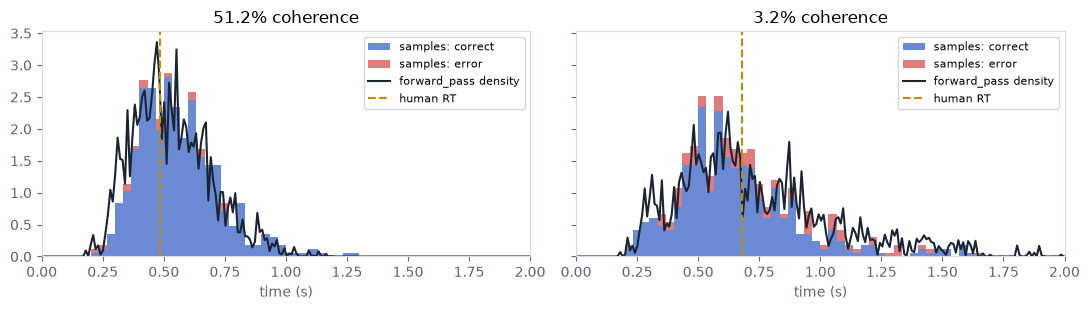

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (name, i) in zip(axes, rdm_trials.items()):
    row = rdm_df.loc[i]
    cov = {'img_embedding': rdm_test.embeddings[i:i + 1].to(device).float()}   # [1, 150, 24]

    seed_all()
    choices, rts = sample_races(rdm, cov, n_samples=500)
    with torch.no_grad():
        choice_probs, density, ts, ndt = rdm.forward_pass(covariates=cov, batch_size=1, n_reps=256)

    print(f"{name}: {row['coherence']}% coherence, dots move {RDM_LABELS[int(row['direction_label'])]}")
    summarise(choices[0], rts[0], RDM_LABELS, int(row['direction_label']), row['rt'])
    print('  forward_pass choice probabilities:', choice_probs[0].cpu().numpy().round(2))
    plot_rt(ax, rts[0], choices[0], int(row['direction_label']), density[0].cpu().numpy(),
            ts.cpu().numpy(), row['rt'], f"{row['coherence']}% coherence", 2.0)
plt.tight_layout(); plt.show()

### The bound Θ(c)
After a call, `model.cond` holds the encoded conditioning and
`model.threshold_net(model.cond)` returns the learned threshold. Because the RDM model is a TimeEmbeddedNRM, the conditioning varies across frames and the threshold is a time series: one value per integration step.

In [5]:
with torch.no_grad():
    for name, i in rdm_trials.items():
        rdm.simulate_nDDM(batch_size=1, n_reps=1,
                          covariates={'img_embedding': rdm_test.embeddings[i:i + 1].to(device).float()})
        theta = rdm.threshold_net(rdm.cond)[0].cpu().numpy()          # [T]
        print(f'{name}: Θ(c) over {theta.size} steps — mean {theta.mean():.3f}, '
              f'range {theta.min():.3f}–{theta.max():.3f}')

easy: Θ(c) over 300 steps — mean 0.532, range 0.529–0.533
hard: Θ(c) over 300 steps — mean 0.532, range 0.527–0.535


### A batch of stimuli
Batched inference: 100 test trials per coherence, 20 independent races each.

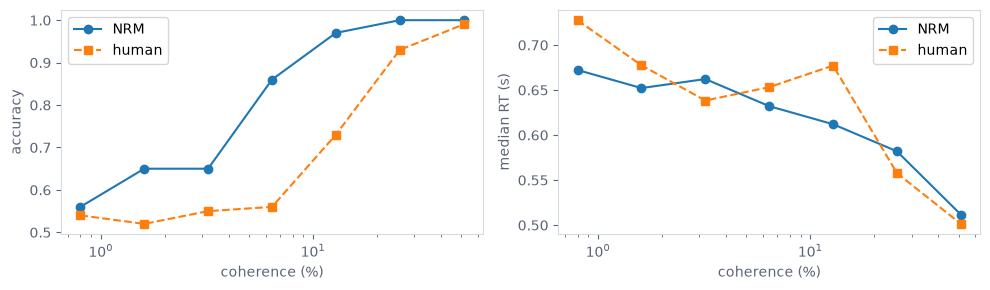

In [6]:
from scripts.tables import RDM_COHERENCES

seed_all()
rows = []
for coh in RDM_COHERENCES:
    sub = rdm_df[np.isclose(rdm_df['coherence'], coh)].sample(100, random_state=SEED)
    with torch.no_grad():
        _, _, choice, rt = rdm.simulate_nDDM(
            batch_size=len(sub), n_reps=20, soft=True, t=0.993,
            covariates={'img_embedding': rdm_test.embeddings[sub.index.to_numpy(copy=True)].to(device).float()})
    rows.append((coh, (choice.cpu().numpy() == sub['direction_label'].values).mean(),
                 sub['correct'].mean(), np.median(rt.cpu().numpy()), sub['rt'].median()))
rows = np.array(rows)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
a1.plot(rows[:, 0], rows[:, 1], 'o-', label='NRM'); a1.plot(rows[:, 0], rows[:, 2], 's--', label='human')
a1.set(xscale='log', xlabel='coherence (%)', ylabel='accuracy'); a1.legend()
a2.plot(rows[:, 0], rows[:, 3], 'o-', label='NRM'); a2.plot(rows[:, 0], rows[:, 4], 's--', label='human')
a2.set(xscale='log', xlabel='coherence (%)', ylabel='median RT (s)'); a2.legend()
plt.tight_layout(); plt.show()

### The race
The two trials above as animations: the dot video (drawn with 60 dots
instead of the experiment's 6, for legibility), one sampled accumulator path per 
alternative, the threshold, the NRM crossing time and the human RT.

Loading RDM metadata from datasets/rdm/rdm_nrm_dataset.pkl ...
Loading embeddings from embeddings/rdm/rdm_embeddings.pt ...
RT outlier removal (MAD per coherence, thresh=3.0, min_rt=0.05s, max_rt=3.0s): 3386 removed, 55052 remaining.
  train:  44161 trials
  val  :   5453 trials
  test :   5438 trials


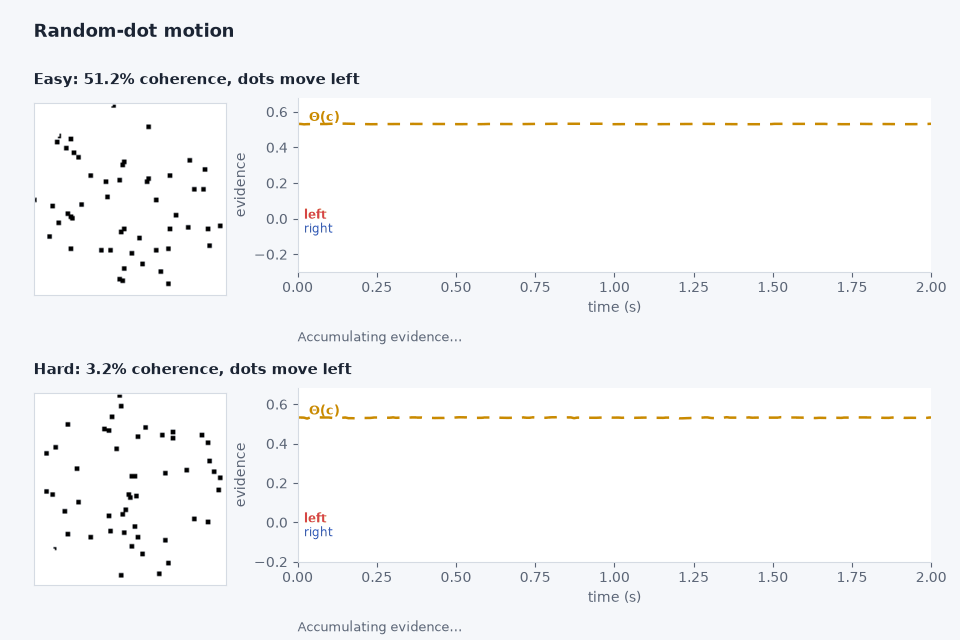

In [7]:
from tutorial.make_gifs import rdm_rows, sc_rows, sat_rows
from tutorial.race_viz import animate

display(Image(filename=animate(rdm_rows(), ROOT / 'assets/nrm_rdm.gif',
                               title='Random-dot motion', t_max=2.0)))

## 2. Scene categorisation

### Model and embeddings
For SC, the NRM is conditioned on a time-independent vector rather than a temporal sequence. Discriminability (0.2–1.0) controls how clearly each stimulus belongs to one of the two categories: natural or man-made.

In [8]:
from datasets.sc.loader import SCDataset

sc = load_nrm('sc', 'NRM_sc.pt')
SC_LABELS = ['natural', 'man-made']

sc_ds = SCDataset(csv_path=str(ROOT / 'datasets/sc/experiment_1.csv'),
                  image_dir=str(ROOT / 'datasets/sc/stimuli'), load_images=False)
_, _, sc_test = sc_ds.train_val_test_split(val_size=0.10, test_size=0.20, seed=42)
sc_test.embeddings = torch.load(ROOT / 'embeddings/sc/sc_embeddings.pt', weights_only=False)['test']
sc_df = sc_test.df.reset_index(drop=True)
sc_df['_correct'], sc_df['_rt'] = (sc_df['human_choice'] == sc_df['choice']).astype(int), sc_df['rt']

rng = np.random.default_rng(SEED)
sc_trials = {name: typical_trial(sc_df, sc_df['cat'] == cat, rng)
             for name, cat in (('easy', 'natural_100'), ('hard', 'natural_20'))}
print(type(sc).__name__, '| choices:', sc.n_choices, '| embeddings:', tuple(sc_test.embeddings.shape))
sc_df.loc[list(sc_trials.values()), ['img', 'prob', 'choice', 'rt']]

bad_trial removal: 383 rows removed, 7297 remaining.
Dataset ready: 7297 trials, 960 unique images, 8 subjects.
  train: 5105 trials (672 images)
  val  : 727 trials (96 images)
  test : 1465 trials (192 images)
NRM | choices: 2 | embeddings: (1465, 18)


,img,prob,choice,rt
240,natural_100/sun_avzzdycklcqmqqaz.jpg,1.0,0,0.361
1044,natural_20/sun_affmpemhrtxghumz.jpg,0.2,0,0.402


### Inference on one stimulus
`covariates = {'img_embedding': [1, 18]}`.

easy: natural_100/sun_avzzdycklcqmqqaz.jpg (discriminability 1.0)
  P(choice): natural 0.79, man-made 0.21
  P(correct = natural): 0.79
  model RT: median 341 ms (IQR 188–632 ms)   ·   human RT 361 ms
  forward_pass choice probabilities: [0.99 0.01]
hard: natural_20/sun_affmpemhrtxghumz.jpg (discriminability 0.2)
  P(choice): man-made 0.51, natural 0.49
  P(correct = natural): 0.49
  model RT: median 361 ms (IQR 211–544 ms)   ·   human RT 402 ms
  forward_pass choice probabilities: [0.95 0.05]


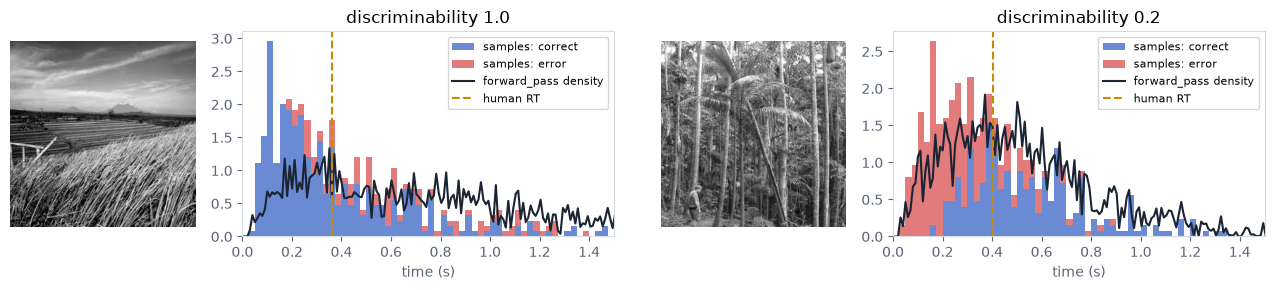

In [9]:
from PIL import Image as PILImage

fig, axes = plt.subplots(1, 4, figsize=(13, 3), gridspec_kw={'width_ratios': [1, 2, 1, 2]})
for k, (name, i) in enumerate(sc_trials.items()):
    row = sc_df.loc[i]
    cov = {'img_embedding': sc_test.embeddings[i:i + 1].to(device).float()}    # [1, 18]

    seed_all()
    choices, rts = sample_races(sc, cov, n_samples=500)
    with torch.no_grad():
        choice_probs, density, ts, ndt = sc.forward_pass(covariates=cov, batch_size=1, n_reps=256)

    print(f"{name}: {row['img']} (discriminability {row['prob']})")
    summarise(choices[0], rts[0], SC_LABELS, int(row['choice']), row['rt'])
    print('  forward_pass choice probabilities:', choice_probs[0].cpu().numpy().round(2))
    axes[2 * k].imshow(PILImage.open(ROOT / 'datasets/sc/stimuli' / row['img']), cmap='gray')
    axes[2 * k].axis('off')
    plot_rt(axes[2 * k + 1], rts[0], choices[0], int(row['choice']), density[0].cpu().numpy(),
            ts.cpu().numpy(), row['rt'], f"discriminability {row['prob']}", 1.5)
plt.tight_layout(); plt.show()

### A batch of stimuli
The whole test split in one call per discriminability level, 20 races per
stimulus.

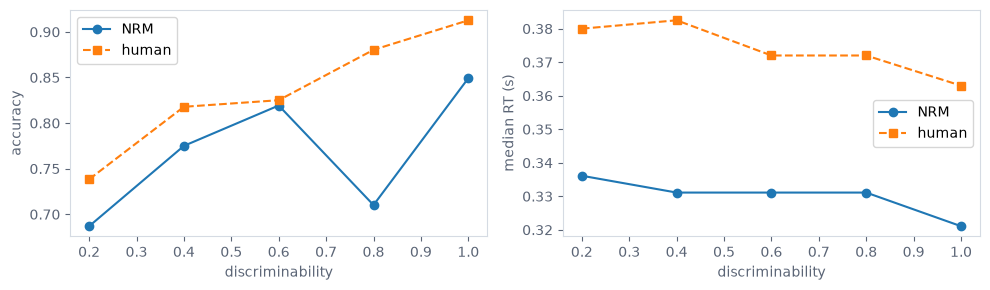

In [10]:
seed_all()
rows = []
for prob in sorted(sc_df['prob'].unique()):
    sub = sc_df[sc_df['prob'] == prob]
    with torch.no_grad():
        _, _, choice, rt = sc.simulate_nDDM(
            batch_size=len(sub), n_reps=20, soft=True, t=0.993,
            covariates={'img_embedding': sc_test.embeddings[sub.index.to_numpy(copy=True)].to(device).float()})
    rows.append((prob, (choice.cpu().numpy() == sub['choice'].values).mean(),
                 sub['_correct'].mean(), np.median(rt.cpu().numpy()), sub['rt'].median()))
rows = np.array(rows)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
a1.plot(rows[:, 0], rows[:, 1], 'o-', label='NRM'); a1.plot(rows[:, 0], rows[:, 2], 's--', label='human')
a1.set(xlabel='discriminability', ylabel='accuracy'); a1.legend()
a2.plot(rows[:, 0], rows[:, 3], 'o-', label='NRM'); a2.plot(rows[:, 0], rows[:, 4], 's--', label='human')
a2.set(xlabel='discriminability', ylabel='median RT (s)'); a2.legend()
plt.tight_layout(); plt.show()

### The race

bad_trial removal: 383 rows removed, 7297 remaining.
Dataset ready: 7297 trials, 960 unique images, 8 subjects.
  train: 5105 trials (672 images)
  val  : 727 trials (96 images)
  test : 1465 trials (192 images)


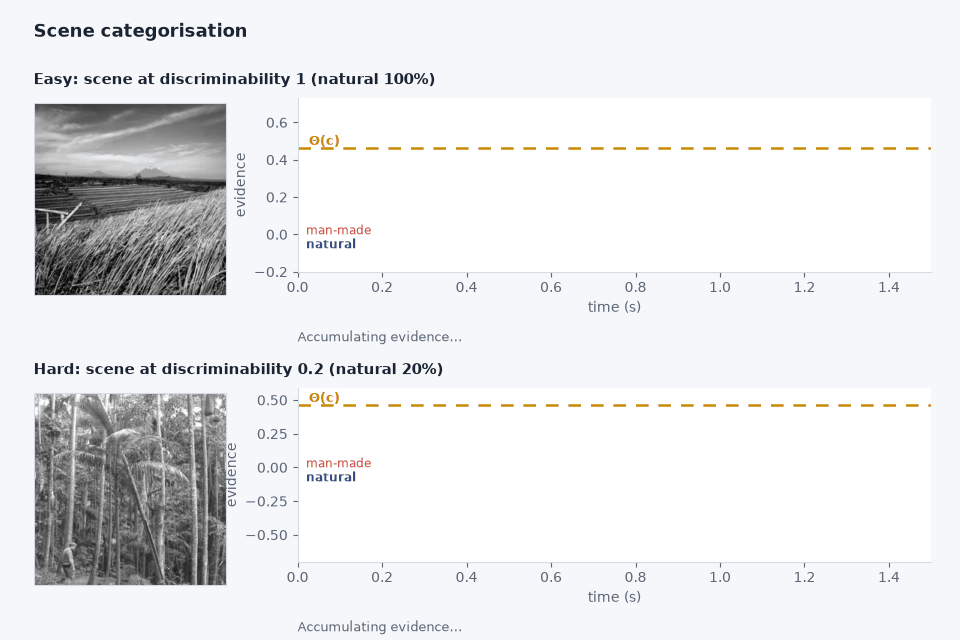

In [11]:
display(Image(filename=animate(sc_rows(), ROOT / 'assets/nrm_sc.gif',
                               title='Scene categorisation', t_max=1.5)))

## 3. Speed–accuracy trade-off

### Model and embeddings
One `NRM` per perturbation (blur, colour, noise), 16 accumulators. The
conditioning has **two inputs**: the 384-d DINOv2 embedding of the image
(`'img_embedding'`) and the response **deadline in seconds** (`'time_limit'`,
shape `[B, 1]`). `embeddings/sat/sat_color_blur_embeddings.pt` stores one embedding per trial.

In [12]:
from datasets.sat.loader import CATEGORIES, SATDataset

sat = load_nrm('sat', 'NRM_sat_blur.pth')

sat_ds = SATDataset(file_path=str(ROOT / 'datasets/sat/color-blur.txt'),
                    image_dir=str(ROOT / 'datasets/sat/data'), load_images=False)
sat_emb = torch.load(ROOT / 'embeddings/sat/sat_color_blur_embeddings.pt', weights_only=False)
assert all(Path(a).parts[-2:] == Path(b).parts[-2:]
           for a, b in zip(sat_ds.df['image_path'], sat_emb['image_paths']))
sat_ds.embeddings = sat_emb['embeddings']                  # [trials, 384]
all_trials = sat_ds.df.copy()                              # every human response, for reference

sat_ds.remove_rt_outliers(outlier_range_ms=[-100, 100])
keep = (sat_ds.df['block'] != 'cattut').to_numpy(copy=True)
sat_ds.embeddings, sat_ds.df = sat_ds.embeddings[torch.from_numpy(keep)], sat_ds.df[keep].reset_index(drop=True)
_, _, sat_test = sat_ds.train_val_test_split(val_size=0.1, test_size=0.2, seed=42)

print(type(sat).__name__, '| choices:', sat.n_choices, '| test embeddings:', tuple(sat_test.embeddings.shape))
print('deadlines (ms):', sorted(int(t) for t in sat_test.df['time_limit'].unique()))

File read: 45 subjects found.
Dataset ready: 47250 total trials.
RT outlier removal ([-100, +100] ms from beep): 28127 removed, 19123 remaining.
  test : 3374 trials
  val  : 1687 trials
  train: 11812 trials
NRM | choices: 16 | test embeddings: (3374, 384)
deadlines (ms): [500, 900, 1100, 1300, 1500]


### One image, five deadlines
A boat at blur σ = 3. The deadline is included as a conditioning variable: the same stimulus embedding is paired with each deadline condition under which it was presented.

deadline 500 ms — humans: 0% correct, median RT 627 ms (n=44)
  P(choice): boat 0.49, bear 0.39, chair 0.07
  P(correct = boat): 0.49
  model RT: median 661 ms (IQR 391–1105 ms)
deadline 1100 ms — humans: 60% correct, median RT 1177 ms (n=42)
  P(choice): boat 0.91, bear 0.06, chair 0.03
  P(correct = boat): 0.91
  model RT: median 1227 ms (IQR 1080–1413 ms)
deadline 1500 ms — humans: 72% correct, median RT 1480 ms (n=43)
  P(choice): boat 0.99, chair 0.01, knife 0.00
  P(correct = boat): 0.99
  model RT: median 1363 ms (IQR 1260–1485 ms)


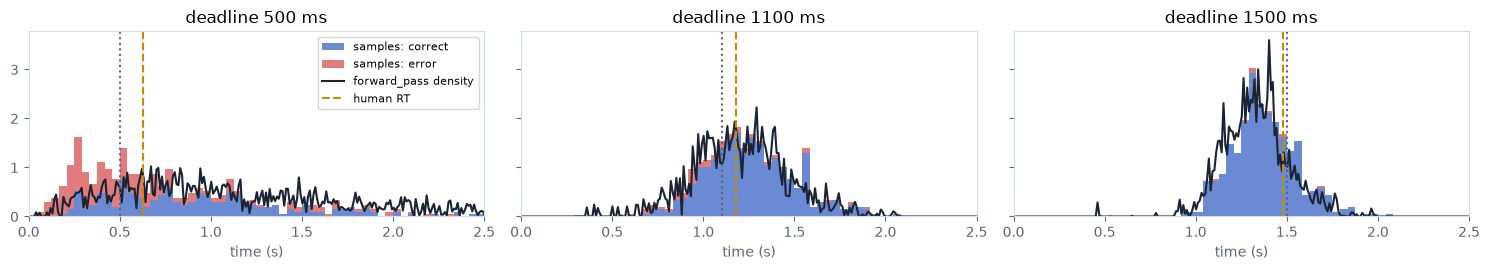

In [13]:
IMAGE = '113_blur_3_boat.JPEG'
target = CATEGORIES.index('boat')
img_trials = all_trials[(all_trials['filename'] == IMAGE) & (all_trials['time_limit'] > 0)]
emb = sat_emb['embeddings'][img_trials.index[0]].view(1, -1).to(device).float()     # [1, 384]

deadlines = sorted(int(t) for t in img_trials['time_limit'].unique())
fig, axes = plt.subplots(1, len(deadlines), figsize=(15, 2.8), sharey=True)
for ax, tl in zip(axes, deadlines):
    cov = {'img_embedding': emb, 'time_limit': torch.tensor([[tl / 1000.0]], device=device)}
    seed_all()
    choices, rts = sample_races(sat, cov, n_samples=500)
    with torch.no_grad():
        _, density, ts, _ = sat.forward_pass(covariates=cov, batch_size=1, n_reps=256)
    humans = img_trials[img_trials['time_limit'] == tl]
    print(f'deadline {tl} ms — humans: {(humans["response"] == "boat").mean():.0%} correct, '
          f'median RT {humans["duration"].median():.0f} ms (n={len(humans)})')
    summarise(choices[0], rts[0], CATEGORIES, target)
    plot_rt(ax, rts[0], choices[0], target, density[0].cpu().numpy(), ts.cpu().numpy(),
            humans['duration'].median() / 1000, f'deadline {tl} ms', 2.5)
    ax.axvline(tl / 1000, color='#5B6576', ls=':')
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.tight_layout(); plt.show()

### The speed–accuracy curve
All blur-3 test trials are evaluated in a single batched call per deadline, with 20 races per trial. Accuracy increases with the deadline for both the model and human participants.

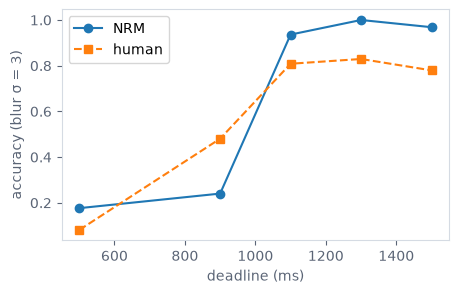

In [14]:
seed_all()
rows = []
sat_tdf = sat_test.df
for tl in sorted(int(t) for t in sat_tdf['time_limit'].unique()):
    sub = sat_tdf[(sat_tdf['level_str'] == '3') & (sat_tdf['time_limit'] == tl)]
    emb_b = sat_test.embeddings[sub.index.to_numpy(copy=True)].to(device).float()
    tl_b = torch.full((len(sub), 1), tl / 1000.0, device=device)
    with torch.no_grad():
        _, _, choice, rt = sat.simulate_nDDM(batch_size=len(sub), n_reps=20, soft=True, t=0.993,
                                             covariates={'img_embedding': emb_b, 'time_limit': tl_b})
    rows.append((tl, (choice.cpu().numpy() == sub['choice'].values).mean(),
                 (sub['response'] == sub['category']).mean()))
rows = np.array(rows)
plt.figure(figsize=(5, 3))
plt.plot(rows[:, 0], rows[:, 1], 'o-', label='NRM'); plt.plot(rows[:, 0], rows[:, 2], 's--', label='human')
plt.xlabel('deadline (ms)'); plt.ylabel('accuracy (blur σ = 3)'); plt.legend(); plt.show()

### The race
The ImageNet stimuli cannot be redistributed, so the panel shows a CC0 photo
of the same category ([Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Blue_fishing_boat_harbour_Eretria_Euboea_Greece.jpg))
with the trial's perturbation (greyscale, blur σ = 3) applied using `datasets/sat/generate_images.py`. The race is still simulated on the original ImageNet image. Target in blue, distractors in grey (a distractor that wins turns
red).

File read: 45 subjects found.
Dataset ready: 47250 total trials.


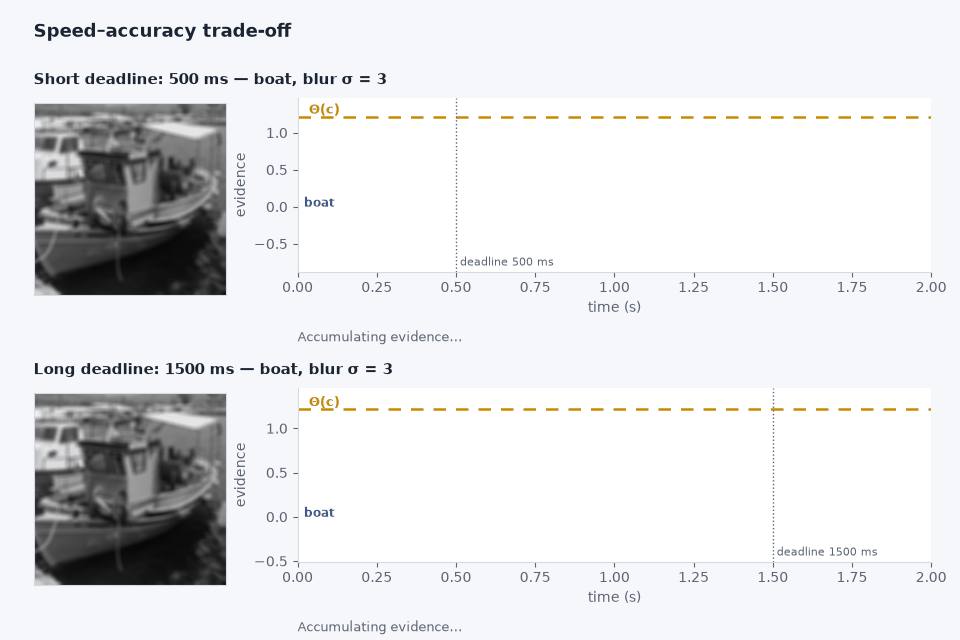

In [15]:
display(Image(filename=animate(sat_rows(task='color-blur', category='boat', level='3',
                                        filename=IMAGE),
                               ROOT / 'assets/nrm_sat.gif', title='Speed–accuracy trade-off',
                               t_max=2.0)))

## Your own stimuli
To apply a trained NRM to new stimuli, first compute their embeddings using the same pipeline used for the corresponding task (`embeddings/<task>/compute_embeddings.py`). RDM uses motion-energy features, while SC and SAT use DINOv2-S/14 embeddings. Pass the resulting embeddings as covariates, as shown in the examples above.